In [2]:
# Import libraries
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import datetime
import sqlite3
import numpy as np
from scipy import stats
from itertools import combinations
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Import the data

> https://www.transtats.bts.gov/OT_Delay/OT_DelayCause1.asp

Navigate to "Database Tables" > Reporting Carrier On-Time Performance (1987-present)

Select all fields from Year to DivDistance (inclusive) and download the dataset for August 2025 - July 2026

Alternatively, unzip data.zip and place all the csv files in /data

In [3]:
files = [ "08_2025", "09_2025", "10_2025", "11_2025", "12_2025", "01_2026", "02_2026", "03_2026", "04_2026", "05_2026", "06_2026", "07_2026" ]
flights_df = pd.DataFrame()

for name in files:
    print("Loading", name)
    loaded_df = pd.read_csv(f'./data/{name}.csv', dtype={48: str})
    flights_df = pd.concat([flights_df, loaded_df], verify_integrity=False)

flights_df.to_csv("./data/flights.csv")

Loading 08_2025
Loading 09_2025
Loading 10_2025
Loading 11_2025
Loading 12_2025
Loading 01_2026
Loading 02_2026
Loading 03_2026
Loading 04_2026
Loading 05_2026
Loading 06_2026
Loading 07_2026


# Cleaning the Data

First we need to load our data. Then, we can take a look at what values are NaN/missing.

In [4]:
flights_df = pd.read_csv("./data/flights.csv", dtype={49: str}, index_col=0)

display(flights_df.head(5))
flights_df.isna().sum()

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,ORIGIN_WAC,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DELAY_NEW,DEP_DEL15,DEP_DELAY_GROUP,DEP_TIME_BLK,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DELAY_NEW,ARR_DEL15,ARR_DELAY_GROUP,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,FLIGHTS,DISTANCE,DISTANCE_GROUP,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,FIRST_DEP_TIME,TOTAL_ADD_GTIME,LONGEST_ADD_GTIME,DIV_AIRPORT_LANDINGS,DIV_REACHED_DEST,DIV_ACTUAL_ELAPSED_TIME,DIV_ARR_DELAY,DIV_DISTANCE
0,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N101NN,28,12892,1289209,32575,LAX,"Los Angeles, CA",CA,6,California,91,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,2252,2253.0,1.0,1.0,0.0,0.0,2200-2259,16.0,2309.0,658.0,8.0,729,706.0,-23.0,0.0,0.0,-2.0,0700-0759,0.0,NaN,0.0,337.0,313.0,289.0,1.0,2475.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
1,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N101NN,302,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,12892,1289209,32575,LAX,"Los Angeles, CA",CA,6,California,91,1745,1734.0,-11.0,0.0,0.0,-1.0,1700-1759,41.0,1815.0,2042.0,9.0,2056,2051.0,-5.0,0.0,0.0,-1.0,2000-2059,0.0,NaN,0.0,371.0,377.0,327.0,1.0,2475.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
2,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N101NN,307,12892,1289209,32575,LAX,"Los Angeles, CA",CA,6,California,91,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,745,746.0,1.0,1.0,0.0,0.0,0700-0759,14.0,800.0,1542.0,24.0,1625,1606.0,-19.0,0.0,0.0,-2.0,1600-1659,0.0,NaN,0.0,340.0,320.0,282.0,1.0,2475.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
3,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N102NN,166,14771,1477104,32457,SFO,"San Francisco, CA",CA,6,California,91,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,1317,1309.0,-8.0,0.0,0.0,-1.0,1300-1359,25.0,1334.0,2119.0,8.0,2159,2127.0,-32.0,0.0,0.0,-2.0,2100-2159,0.0,NaN,0.0,342.0,318.0,285.0,1.0,2586.0,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
4,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N102NN,179,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,14771,1477104,32457,SFO,"San Francisco, CA",CA,6,California,91,800,753.0,-7.0,0.0,0.0,-1.0,0800-0859,27.0,820.0,1108.0,11.0,1132,1119.0,-13.0,0.0,0.0,-1.0,1100-1159,0.0,NaN,0.0,392.0,386.0,348.0,1.0,2586.0,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN


YEAR                             0
QUARTER                          0
MONTH                            0
DAY_OF_MONTH                     0
DAY_OF_WEEK                      0
FL_DATE                          0
OP_UNIQUE_CARRIER                0
OP_CARRIER_AIRLINE_ID            0
OP_CARRIER                       0
TAIL_NUM                     17774
OP_CARRIER_FL_NUM                0
ORIGIN_AIRPORT_ID                0
ORIGIN_AIRPORT_SEQ_ID            0
ORIGIN_CITY_MARKET_ID            0
ORIGIN                           0
ORIGIN_CITY_NAME                 0
ORIGIN_STATE_ABR                 0
ORIGIN_STATE_FIPS                0
ORIGIN_STATE_NM                  0
ORIGIN_WAC                       0
DEST_AIRPORT_ID                  0
DEST_AIRPORT_SEQ_ID              0
DEST_CITY_MARKET_ID              0
DEST                             0
DEST_CITY_NAME                   0
DEST_STATE_ABR                   0
DEST_STATE_FIPS                  0
DEST_STATE_NM                    0
DEST_WAC            

We are examining flights based on their departure and arrival time, so if neither are available we can safely discard them since no data was recorded. There are only a small number of these (< 1%)

We can also fix the delay type fields since they are filled with NaN instead of 0 for no delay.

In [5]:
flights_df.dropna(subset=['DEP_TIME', 'ARR_TIME'], inplace=True) # Drop flights with no departure or arrival time, data was not published (small number)
flights_df['CARRIER_DELAY'] = flights_df['CARRIER_DELAY'].fillna(0) # NaN is no delay
flights_df['WEATHER_DELAY'] = flights_df['WEATHER_DELAY'].fillna(0) # NaN is no delay
flights_df['NAS_DELAY'] = flights_df['NAS_DELAY'].fillna(0) # NaN is no delay
flights_df['SECURITY_DELAY'] = flights_df['SECURITY_DELAY'].fillna(0) # NaN is no delay
flights_df['LATE_AIRCRAFT_DELAY'] = flights_df['LATE_AIRCRAFT_DELAY'].fillna(0) # NaN is no delay

print(flights_df.isna().sum())
display(flights_df[flights_df['DIV_AIRPORT_LANDINGS'].isna()])
print(flights_df['DIV_AIRPORT_LANDINGS'].value_counts(dropna=False))

YEAR                             0
QUARTER                          0
MONTH                            0
DAY_OF_MONTH                     0
DAY_OF_WEEK                      0
FL_DATE                          0
OP_UNIQUE_CARRIER                0
OP_CARRIER_AIRLINE_ID            0
OP_CARRIER                       0
TAIL_NUM                         0
OP_CARRIER_FL_NUM                0
ORIGIN_AIRPORT_ID                0
ORIGIN_AIRPORT_SEQ_ID            0
ORIGIN_CITY_MARKET_ID            0
ORIGIN                           0
ORIGIN_CITY_NAME                 0
ORIGIN_STATE_ABR                 0
ORIGIN_STATE_FIPS                0
ORIGIN_STATE_NM                  0
ORIGIN_WAC                       0
DEST_AIRPORT_ID                  0
DEST_AIRPORT_SEQ_ID              0
DEST_CITY_MARKET_ID              0
DEST                             0
DEST_CITY_NAME                   0
DEST_STATE_ABR                   0
DEST_STATE_FIPS                  0
DEST_STATE_NM                    0
DEST_WAC            

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,ORIGIN_WAC,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DELAY_NEW,DEP_DEL15,DEP_DELAY_GROUP,DEP_TIME_BLK,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DELAY_NEW,ARR_DEL15,ARR_DELAY_GROUP,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,FLIGHTS,DISTANCE,DISTANCE_GROUP,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,FIRST_DEP_TIME,TOTAL_ADD_GTIME,LONGEST_ADD_GTIME,DIV_AIRPORT_LANDINGS,DIV_REACHED_DEST,DIV_ACTUAL_ELAPSED_TIME,DIV_ARR_DELAY,DIV_DISTANCE
27791,2026,3,7,2,4,7/2/2026 12:00:00 AM,F9,20436,F9,N638FR,2791,13204,1320403,31454,MCO,"Orlando, FL",FL,12,Florida,33,13930,1393008,30977,ORD,"Chicago, IL",IL,17,Illinois,41,2101,2052.0,-9.0,0.0,0.0,-1.0,2100-2159,13.0,2105.0,302.0,17.0,2319,319.0,240.0,240.0,1.0,12.0,2300-2359,0.0,NaN,0.0,198.0,447.0,417.0,1.0,1005.0,5,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


DIV_AIRPORT_LANDINGS
0.0    6895391
1.0      17501
9.0        118
2.0        104
3.0          2
NaN          1
Name: count, dtype: int64


There is still one flight that has a NaN number of airport landings. It looks like this flight has no diversion data anyways, so it did not divert. The standard value for this is 0, not NaN, so we can correct it.

In [6]:
flights_df['DIV_AIRPORT_LANDINGS'] = flights_df['DIV_AIRPORT_LANDINGS'].fillna(0)
print(flights_df['DIV_AIRPORT_LANDINGS'].value_counts(dropna=False))

DIV_AIRPORT_LANDINGS
0.0    6895392
1.0      17501
9.0        118
2.0        104
3.0          2
Name: count, dtype: int64


Let's parse our data now! First, we need to look at what types we're working with.

In [7]:
print(flights_df.dtypes)
display(flights_df.sample(10))

YEAR                         int64
QUARTER                      int64
MONTH                        int64
DAY_OF_MONTH                 int64
DAY_OF_WEEK                  int64
FL_DATE                     object
OP_UNIQUE_CARRIER           object
OP_CARRIER_AIRLINE_ID        int64
OP_CARRIER                  object
TAIL_NUM                    object
OP_CARRIER_FL_NUM            int64
ORIGIN_AIRPORT_ID            int64
ORIGIN_AIRPORT_SEQ_ID        int64
ORIGIN_CITY_MARKET_ID        int64
ORIGIN                      object
ORIGIN_CITY_NAME            object
ORIGIN_STATE_ABR            object
ORIGIN_STATE_FIPS            int64
ORIGIN_STATE_NM             object
ORIGIN_WAC                   int64
DEST_AIRPORT_ID              int64
DEST_AIRPORT_SEQ_ID          int64
DEST_CITY_MARKET_ID          int64
DEST                        object
DEST_CITY_NAME              object
DEST_STATE_ABR              object
DEST_STATE_FIPS              int64
DEST_STATE_NM               object
DEST_WAC            

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,ORIGIN_WAC,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DELAY_NEW,DEP_DEL15,DEP_DELAY_GROUP,DEP_TIME_BLK,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DELAY_NEW,ARR_DEL15,ARR_DELAY_GROUP,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,FLIGHTS,DISTANCE,DISTANCE_GROUP,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,FIRST_DEP_TIME,TOTAL_ADD_GTIME,LONGEST_ADD_GTIME,DIV_AIRPORT_LANDINGS,DIV_REACHED_DEST,DIV_ACTUAL_ELAPSED_TIME,DIV_ARR_DELAY,DIV_DISTANCE
521022,2026,3,7,26,7,7/26/2026 12:00:00 AM,UA,19977,UA,N17229,2442,11193,1119302,33105,CVG,"Cincinnati, OH",KY,21,Kentucky,52,12266,1226604,31453,IAH,"Houston, TX",TX,48,Texas,74,635,635.0,0.0,0.0,0.0,0.0,0600-0659,14.0,649.0,739.0,6.0,811,745.0,-26.0,0.0,0.0,-2.0,0800-0859,0.0,NaN,0.0,156.0,130.0,110.0,1.0,871.0,4,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
496529,2026,2,6,25,4,6/25/2026 12:00:00 AM,OO,20304,OO,N138SY,5886,11292,1129203,30325,DEN,"Denver, CO",CO,8,Colorado,82,14783,1478302,34783,SGF,"Springfield, MO",MO,29,Missouri,64,1738,1749.0,11.0,11.0,0.0,0.0,1700-1759,34.0,1823.0,2113.0,8.0,2043,2121.0,38.0,38.0,1.0,2.0,2000-2059,0.0,NaN,0.0,125.0,152.0,110.0,1.0,637.0,3,11.0,0.0,27.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
348135,2025,4,12,19,5,12/19/2025 12:00:00 AM,OO,20304,OO,N740SK,6447,11298,1129806,30194,DFW,"Dallas/Fort Worth, TX",TX,48,Texas,74,14674,1467403,34674,SAF,"Santa Fe, NM",NM,35,New Mexico,86,1124,1118.0,-6.0,0.0,0.0,-1.0,1100-1159,18.0,1136.0,1158.0,4.0,1224,1202.0,-22.0,0.0,0.0,-2.0,1200-1259,0.0,NaN,0.0,120.0,104.0,82.0,1.0,551.0,3,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
50739,2026,1,2,3,2,2/3/2026 12:00:00 AM,WN,19393,WN,N8699A,4174,10821,1082106,30852,BWI,"Baltimore, MD",MD,24,Maryland,35,12889,1288904,32211,LAS,"Las Vegas, NV",NV,32,Nevada,85,755,756.0,1.0,1.0,0.0,0.0,0700-0759,9.0,805.0,1009.0,4.0,1035,1013.0,-22.0,0.0,0.0,-2.0,1000-1059,0.0,NaN,0.0,340.0,317.0,304.0,1.0,2106.0,9,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
214757,2025,4,12,12,5,12/12/2025 12:00:00 AM,NK,20416,NK,N630NK,1000,14100,1410006,34100,PHL,"Philadelphia, PA",PA,42,Pennsylvania,23,11057,1105704,31057,CLT,"Charlotte, NC",NC,37,North Carolina,36,600,555.0,-5.0,0.0,0.0,-1.0,0600-0659,10.0,605.0,725.0,5.0,800,730.0,-30.0,0.0,0.0,-2.0,0800-0859,0.0,NaN,0.0,120.0,95.0,80.0,1.0,449.0,2,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
246401,2025,4,10,13,1,10/13/2025 12:00:00 AM,OO,20304,OO,N186SY,3282,14771,1477104,32457,SFO,"San Francisco, CA",CA,6,California,91,11884,1188402,31884,GEG,"Spokane, WA",WA,53,Washington,93,1053,1052.0,-1.0,0.0,0.0,-1.0,1000-1059,31.0,1123.0,1258.0,18.0,1304,1316.0,12.0,12.0,0.0,0.0,1300-1359,0.0,NaN,0.0,131.0,144.0,95.0,1.0,733.0,3,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
401540,2026,3,7,20,1,7/20/2026 12:00:00 AM,WN,19393,WN,N7741C,3014,13796,1379611,32457,OAK,"Oakland, CA",CA,6,California,91,11259,1125905,30194,DAL,"Dallas, TX",TX,48,Texas,74,1100,1057.0,-3.0,0.0,0.0,-1.0,1100-1159,12.0,1109.0,1624.0,3.0,1625,1627.0,2.0,2.0,0.0,0.0,1600-1659,0.0,NaN,0.0,205.0,210.0,195.0,1.0,1468.0,6,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
303710,2025,3,9,17,3,9/17/2025 12:00:00 AM,DL,19790,DL,N920DU,933,10397,1039708,30397,ATL,"Atlanta, GA",GA,13,Georgia,34,14831,1483106,32457,SJC,"San Jose, CA",CA,6,California,91,2056,2049.0,-7.0,0.0,0.0,-1.0,2000-2059,16.0,2105.0,2234.0,3.0,2250,2237.0,-13.0,0.0,0.0,-1.0,2200-2259,0.0,NaN,0.0,294.0,288.0,269.0,1.0,2116.0,9,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
117976,2025,4,11,7,5,11/

Our FL_DATE is a string, not a date object. It also does not include the departure time. Let's convert it using the individual components after we verify their ranges make sense, and add it to a column named "SCHEDULED_DATE". We should use CRS_DEP_TIME (formatted hhmm) since we want to know the scheduled time before any delays.

Unfortunately, this data is also messy and does not follow the format exactly. Instead, we will need to format the values (1 to 2359) by padding them with leading 0s to match the format. For example: 1 should become 0001 (or 00:01)

In [8]:
def create_date(row):
    return datetime.datetime(row['YEAR'], row['MONTH'], row['DAY_OF_MONTH'], hour=int(row['CRS_DEP_TIME'][:2]), minute=int(row['CRS_DEP_TIME'][2:]))

# Look at current distribution
print("Departure Time:", flights_df['CRS_DEP_TIME'].min(), "-", flights_df['CRS_DEP_TIME'].max())
print("Year:", flights_df['YEAR'].min(), "-", flights_df['YEAR'].max())
print("Month:", flights_df['MONTH'].min(), "-", flights_df['MONTH'].max())
print("Day:", flights_df['DAY_OF_MONTH'].min(), "-", flights_df['DAY_OF_MONTH'].max())

# Clean up the departure time
flights_df['CRS_DEP_TIME'] = flights_df['CRS_DEP_TIME'].astype(str).apply(lambda x: x.zfill(4))
print(flights_df['CRS_DEP_TIME'].sample(10))

# Convert to date
flights_df.drop(columns=['FL_DATE'], inplace=True)
flights_df['DATE'] = flights_df.apply(create_date, axis=1)
display(flights_df[['DATE', 'CRS_DEP_TIME']].sample(10))

Departure Time: 1 - 2359
Year: 2025 - 2026
Month: 1 - 12
Day: 1 - 31
227586    1812
37482     1400
262538    1839
307987    1630
526491    1720
509898    1100
232096    0540
392992    1110
354851    1259
30688     0715
Name: CRS_DEP_TIME, dtype: object


,DATE,CRS_DEP_TIME
35374,2025-09-02 18:50:00,1850
325776,2026-07-17 14:24:00,1424
216955,2025-08-11 07:45:00,0745
548377,2025-08-29 14:11:00,1411
390365,2026-06-20 18:16:00,1816
25269,2026-06-02 15:10:00,1510
332116,2025-08-17 11:17:00,1117
220706,2026-01-13 17:59:00,1759
448249,2026-02-25 15:33:00,1533
215275,2026-07-11 18:10:00,1810


The rest of the data is parsed correctly, so we can continue with exporting this to a database!

# Exporting to a Database

We will now export all of our data to an sqlite file using ``to_sql`` to the "Flights" table

In [9]:
conn = sqlite3.connect("database.sqlite")

flights_df.to_sql(name='Flights', con=conn, if_exists='replace')

6913117

Let's verify that our table is setup correctly:

In [10]:
crsr = conn.cursor()
query = "PRAGMA table_info(Flights)"
print(crsr.execute(query).fetchall())

query = "SELECT COUNT(*) FROM Flights"
print("Database Rows:", crsr.execute(query).fetchall()[0][0])
print("DataFrame Rows:", flights_df.shape[0])

[(0, 'index', 'INTEGER', 0, None, 0), (1, 'YEAR', 'INTEGER', 0, None, 0), (2, 'QUARTER', 'INTEGER', 0, None, 0), (3, 'MONTH', 'INTEGER', 0, None, 0), (4, 'DAY_OF_MONTH', 'INTEGER', 0, None, 0), (5, 'DAY_OF_WEEK', 'INTEGER', 0, None, 0), (6, 'OP_UNIQUE_CARRIER', 'TEXT', 0, None, 0), (7, 'OP_CARRIER_AIRLINE_ID', 'INTEGER', 0, None, 0), (8, 'OP_CARRIER', 'TEXT', 0, None, 0), (9, 'TAIL_NUM', 'TEXT', 0, None, 0), (10, 'OP_CARRIER_FL_NUM', 'INTEGER', 0, None, 0), (11, 'ORIGIN_AIRPORT_ID', 'INTEGER', 0, None, 0), (12, 'ORIGIN_AIRPORT_SEQ_ID', 'INTEGER', 0, None, 0), (13, 'ORIGIN_CITY_MARKET_ID', 'INTEGER', 0, None, 0), (14, 'ORIGIN', 'TEXT', 0, None, 0), (15, 'ORIGIN_CITY_NAME', 'TEXT', 0, None, 0), (16, 'ORIGIN_STATE_ABR', 'TEXT', 0, None, 0), (17, 'ORIGIN_STATE_FIPS', 'INTEGER', 0, None, 0), (18, 'ORIGIN_STATE_NM', 'TEXT', 0, None, 0), (19, 'ORIGIN_WAC', 'INTEGER', 0, None, 0), (20, 'DEST_AIRPORT_ID', 'INTEGER', 0, None, 0), (21, 'DEST_AIRPORT_SEQ_ID', 'INTEGER', 0, None, 0), (22, 'DEST_CIT

Now that our data is in our database, we can cleanup the dataframe from memory and continue!

In [11]:
flights_df = None

# Data Exploration & Summary Statistics

## Exploring Arrival Delays

We will explore arrival delays (arr_delay), the delay people really care about when their flight is delayed.

In [3]:
conn = sqlite3.connect("database.sqlite")
crsr = conn.cursor()

query = "SELECT COUNT(arr_delay) FROM Flights"
crsr.execute(query).fetchall()

[(6895510,)]

This is a lot of entries! Let's take a look at what's inside.

In [4]:
flights_df = pd.read_sql_query("SELECT arr_delay, diverted, op_carrier FROM Flights;", conn)

print(flights_df.describe())
flights_df[flights_df['ARR_DELAY'].isna()].head(10)

          ARR_DELAY      DIVERTED
count  6.895510e+06  6.913117e+06
mean   8.111811e+00  2.546897e-03
std    6.065110e+01  5.040249e-02
min   -1.090000e+02  0.000000e+00
25%   -1.600000e+01  0.000000e+00
50%   -6.000000e+00  0.000000e+00
75%    1.100000e+01  0.000000e+00
max    4.336000e+03  1.000000e+00


,ARR_DELAY,DIVERTED,OP_CARRIER
292,NaN,1.0,AA
416,NaN,1.0,AA
604,NaN,1.0,AA
721,NaN,1.0,AA
962,NaN,1.0,AA
980,NaN,1.0,AA
1043,NaN,1.0,AA
1077,NaN,1.0,AA
1168,NaN,1.0,AA
1548,NaN,1.0,AA


We have a problem, some of the arrival delays are NaN! In this dataset, this looks related to the flight being diverted and not arriving at its destination. Let's confirm.

In [5]:
flights_df[(flights_df['ARR_DELAY'].isna()) & (flights_df['DIVERTED'] != 1)].head(10)

,ARR_DELAY,DIVERTED,OP_CARRIER


This theory is correct! For our analysis of the delay, let's only look at flights that actually arrived.

In [6]:
flights_df = pd.read_sql_query("SELECT arr_delay, diverted, op_carrier FROM Flights WHERE diverted = 0;", conn)
flights_df.describe()

,ARR_DELAY,DIVERTED
count,6.895510e+06,6895510.0
mean,8.111811e+00,0.0
std,6.065110e+01,0.0
min,-1.090000e+02,0.0
25%,-1.600000e+01,0.0
50%,-6.000000e+00,0.0
75%,1.100000e+01,0.0
max,4.336000e+03,0.0


Some of our delays are negative. According to the dataset, this means that they arrived early! Let's plot this data to draw some more conclusions.

Text(0.5, 1.0, 'Arrival Delays by Carrier')

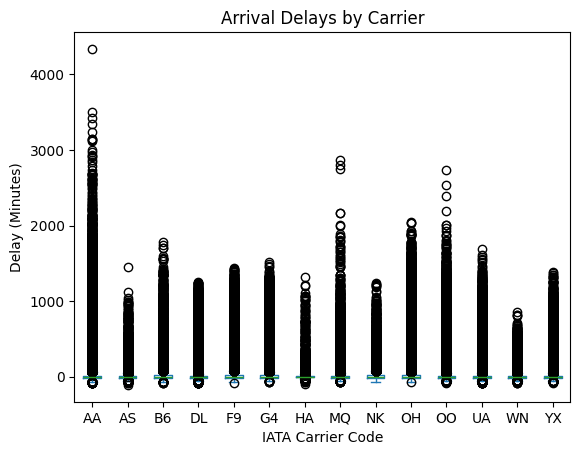

In [7]:
boxplot = flights_df.plot.box(column="ARR_DELAY", by="OP_CARRIER").iloc[0]
boxplot.set_xlabel("IATA Carrier Code")
boxplot.set_ylabel("Delay (Minutes)")
boxplot.set_title("Arrival Delays by Carrier")

It looks like this dataset has a lot of outliers, creating a lot of circles on our box plot! One flight was also delayed for about 3 days, something really bad must have happened. This is not very useful for drawing many conclusions since there are many large values. Let's use a logarithmic scale to take a closer look. Since we do have negative and zero values, we will use symlog.

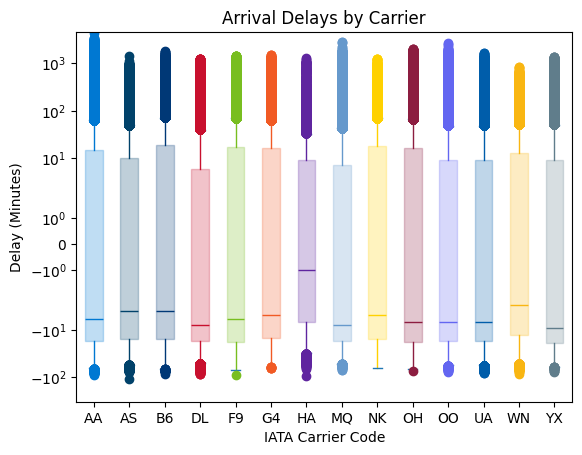

In [8]:
carrier_colors = {
    "AA": "#0078D2",
    "AS": "#01426A",
    "B6": "#003876",
    "DL": "#C8102E",
    "F9": "#78BE20",
    "G4": "#F15A24",
    "HA": "#5F259F",
    "MQ": "#6699CC",
    "NK": "#FFD100",
    "OH": "#8C1D40",
    "OO": "#6366F1",
    "UA": "#005DAA",
    "WN": "#F9B612",
    "YX": "#607D8B"
}

boxplot = flights_df.plot.box(column="ARR_DELAY", by="OP_CARRIER", return_type="dict", patch_artist=True).iloc[0]
plt.xlabel("IATA Carrier Code")
plt.ylabel("Delay (Minutes)")
plt.title("Arrival Delays by Carrier")
plt.yscale('symlog')

# Make it pretty!
for i, color in enumerate(carrier_colors.values()):
    box = boxplot['boxes'][i]
    median = boxplot['medians'][i]
    fliers = boxplot['fliers'][i]

    box.set_color(color)
    box.set_alpha(0.25)
    median.set_color(color)
    fliers.set_markerfacecolor(color)
    fliers.set_markeredgecolor(color)

    # Set every 2 whiskers color
    for whisker in boxplot['whiskers'][2*i : 2*i + 2]:
        whisker.set_color(color)

plt.show()

The median arrival delay will be the most important here since we do have a lot of outlier data.

**Conclusion 1:** The median delay is negative, indicating that most flights arrive early across carriers. 75% of flights have a delay of around 10 minutes or less across carriers as well. All carriers are planning their flights well, so you should not expect any significant delays on your flights!

American Airlines (AA) does have more outlier delays extending beyond 1,000 minutes than the other carriers. There are enough outliers across carriers that it is unlikely these datapoints were incorrectly entered, there may have been some event preventing them from taking off for more than a day.

## Departure Time's Impact on Arrival Delays


This subsection explores Confidence Intervals to find some statistical measure for expected delays over a time interval. This statistical measure is useful for comparing a range of mean values instead of singular hypotheses. We also explore relationships between hour of departure and delays as well as time of day and delays.

However, with such a large dataset, you require preprocessing in order to come up with some realistic conclusion.



In [9]:
# 99% confidence intervals for arrival delay (minutes) and P(delay >= 15 min) by scheduled departure hour

query = "SELECT DATE, ARR_DELAY, ARR_DEL15 FROM Flights WHERE DIVERTED = 0"
timestamp_delay = pd.read_sql_query(query, conn, parse_dates=['DATE'])
timestamp_delay['hour'] = timestamp_delay['DATE'].dt.hour

hourly = timestamp_delay.groupby('hour').agg(count=('ARR_DELAY', 'count'),
                                             mean=('ARR_DELAY', 'mean'),
                                             median=('ARR_DELAY', 'median'),
                                             q1=('ARR_DELAY', lambda x: x.quantile(0.25)),
                                             q3=('ARR_DELAY', lambda x: x.quantile(0.75)),
                                             std=('ARR_DELAY', 'std'),
                                             pct_late=('ARR_DEL15', 'mean'))  # mean of 0/1 = proportion late
hourly['iqr'] = hourly['q3'] - hourly['q1']

# 99% CI for mean delay
se = hourly['std'] / np.sqrt(hourly['count'])
hourly['99%_lower_bound'] = hourly['mean'] - 2.576 * se
hourly['99%_upper_bound'] = hourly['mean'] + 2.576 * se

# 99% CI for P(delay >= 15 min)
p_se = np.sqrt(hourly['pct_late'] * (1 - hourly['pct_late']) / hourly['count'])
hourly['pct_late_lower'] = hourly['pct_late'] - 2.576 * p_se
hourly['pct_late_upper'] = hourly['pct_late'] + 2.576 * p_se
#pct_late_lower and pct_late_upper mean its 15+ minutes late between pct_late_lower * 100 and pct_late_upper *100 percent of the time.
#with 99% confidence.
display(hourly)

,count,mean,median,q1,q3,std,pct_late,iqr,99%_lower_bound,99%_upper_bound,pct_late_lower,pct_late_upper
hour,,,,,,,,,,,,
0,10160,1.342913,-11.0,-21.0,5.00,63.202920,0.168209,26.00,-0.272323,2.958150,0.158649,0.177768
1,3344,3.582835,-11.0,-22.0,6.00,75.568875,0.185407,28.00,0.216513,6.949157,0.168095,0.202719
2,1251,1.358913,-12.0,-23.0,8.00,62.131370,0.204636,31.00,-3.166187,5.884012,0.175254,0.234019
3,654,4.663609,-9.0,-19.0,6.75,70.003063,0.198777,25.75,-2.387770,11.714987,0.158578,0.238976
4,165,3.957576,-11.0,-19.0,5.00,55.169843,0.175758,24.00,-7.106258,15.021409,0.099429,0.252086
5,188230,-3.504038,-12.0,-20.0,-3.00,58.517411,0.083127,17.00,-3.851483,-3.156592,0.081488,0.084766
6,473284,-2.445599,-11.0,-19.0,-1.00,59.306299,0.098495,18.00,-2.667667,-2.223531,0.097379,0.099611
7,512712,-0.870949,-10.0,-18.0,1.00,54.208705,0.125376,19.00,-1.065969,-0.675929,0.124185,0.126568
8,478738,0.299968,-9.0,-18.0,3.00,50.281044,0.144323,21.00,0.112770,0.487166,0.143015,0.145632


Now that we have our dataframe: hourly, we can finally start making some conclusions. We can see that the 99% confidence interval for delays of flights departing at 2 AM is -3.2 minutes to 5.9 minutes, while 9 PM's interval for delays is 14.6 to 15.4 minutes. This suggests that the hour your flight departs will impact your arrival delay.

**Conclusion 2A:** Late is defined by this dataset as a delay greater than 15 minutes. Looking at the percent of flights that were late, the 99% confidence interval for 2 AM is 17.5% to 23.4%, while 9 PM's interval is 29.0 - 29.5%. This suggests that the hour a flight departs is related to how many flights are late.

Here we must embolden our claims with Hypothesis Testing. First, let's see if departure time and the proportion of late flights are related using a Chi-Squared test, since we are working with categorical data (late or not late).

- **Null Hypothesis:** There is no relationship between departure time and the proportion of late flights.

- **Alternative Hypothesis:** There is a relationship between departure time and the proportion of late flights.

In [10]:
c1 = pd.crosstab(timestamp_delay['hour'], timestamp_delay['ARR_DEL15'])
chi2, p, df, _ = stats.chi2_contingency(c1)
print(f"Chi-squared = {chi2:.1f}, dof = {df}, p = {p}")
display(c1)

Chi-squared = 233363.2, dof = 23, p = 0.0


ARR_DEL15,0.0,1.0
hour,,
0,8451,1709
1,2724,620
2,995,256
3,524,130
4,136,29
5,172583,15647
6,426668,46616
7,448430,64282
8,409645,69093


**Conclusion 2B:** The p value is 0.0 (< .05), which shows there's a statistical significance and we reject the null hypothesis that there is no relationship between departure time and the proportion of late flights. However, because we are working with a large dataset and contingency table, Chi-squared is likely to show a statistical significance even for a very small difference. Let's apply Cramér's V, which will give us a value 0-1 showing how strong the association is.

In [11]:
stats.contingency.association(c1, method="cramer")

0.18396405037696714

**Conclusion 2C:** Cramér's V gave a value of 0.184, showing there is a slight association between departure time and proportion of late flights.

Let's narrow our focus and examine the difference in proportion of late flights in the morning (6 AM - 11 AM) compared to the evening (5 PM - 10 PM). To do this, we will use a pooled proportion z-test. This test will work since our sample size is large enough (millions of flights).

- **Null Hypothesis:** The proportion of late flights is the same in the morning and evening.

- **Alternative Hypothesis:** Evening flights have a higher proportion of late flights than morning flights (p1 > p2).

In [12]:
# morning (6-11) vs evening (17-22)... is the evening rate higher?
morning = timestamp_delay[timestamp_delay['hour'].between(6, 11)]['ARR_DEL15'].dropna()
evening = timestamp_delay[timestamp_delay['hour'].between(17, 22)]['ARR_DEL15'].dropna()

p_morning = morning.mean()
p_evening = evening.mean()
n_morning = morning.count()
n_evening = evening.count()

# pooled-proportion assuming that the null hypo is true... that rates are equal.
p_pool = (morning.sum() + evening.sum()) / (n_morning + n_evening)
se = np.sqrt(p_pool * (1 - p_pool) * (1/n_morning + 1/n_evening))

z = (p_evening - p_morning) / se # p1 = p_evening, p2 = p_morning
p = stats.norm.sf(z)  # Right-tailed test (p1 > p2)

print(f"Morning late rate: {p_morning:.1%}, Evening late rate: {p_evening:.1%}")
print(f"z = {z:.2f}, p = {p}")

Morning late rate: 14.9%, Evening late rate: 31.1%
z = 416.00, p = 0.0


**Conclusion 3A:** Once again, we have a p value of 0 (< .05), rejecting the null hypothesis that the proportion of late flights is the same in the morning and evening. Looking at the rate, this information is not surprising since the rate of late flights in the evening is 31%, compared to 15% in the morning. To confirm our suspicions, we can look at a graph:

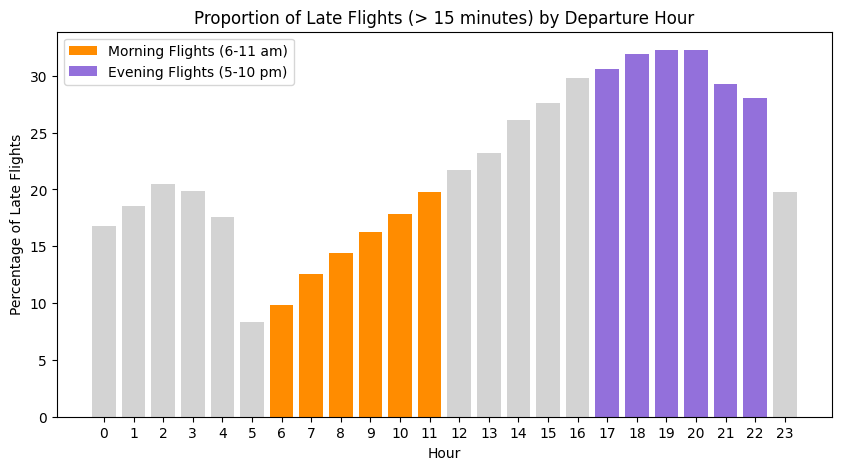

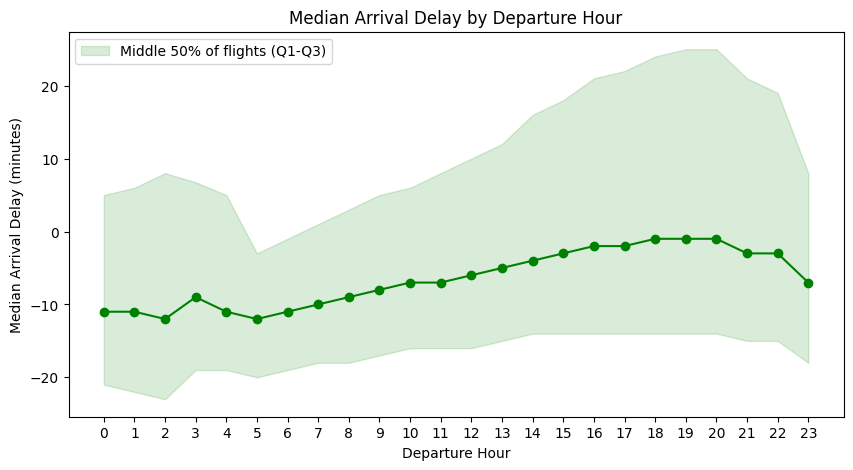

In [13]:
# Morning vs Evening Delays
segment_colors = {
    "morning": "darkorange",
    "evening": "mediumpurple",
    "other": "lightgray"
}

colors = [
    segment_colors["morning"] if 6 <= h <= 11
    else segment_colors["evening"] if 17 <= h <= 22
    else segment_colors["other"]
    for h in hourly.index
]

plt.figure(figsize=(10, 5))
plt.bar(hourly.index, hourly['pct_late'] * 100, color=colors)
plt.xticks(range(24))
plt.xlabel('Hour')
plt.ylabel('Percentage of Late Flights')
plt.title('Proportion of Late Flights (> 15 minutes) by Departure Hour')
legend_items = [
    Patch(facecolor=segment_colors["morning"], label="Morning Flights (6-11 am)"),
    Patch(facecolor=segment_colors["evening"], label="Evening Flights (5-10 pm)"),
]
plt.legend(handles=legend_items)
plt.show()

# Medians plot with IQR band
plt.figure(figsize=(10,5))
plt.plot(hourly.index, hourly['median'], color='green', marker='o')
plt.fill_between(hourly.index, hourly['q1'], hourly['q3'], color='green', alpha=0.15, label="Middle 50% of flights (Q1-Q3)")
plt.xticks(range(24))
plt.xlabel('Departure Hour')
plt.ylabel('Median Arrival Delay (minutes)')
plt.title('Median Arrival Delay by Departure Hour')
plt.legend()
plt.show()

**Conclusion 3B:** Looking at the proportion of late flights in the first graph, we can clearly see a trend that the proportion of late flights in the evening is greater compared to the morning. This confirms our earlier analysis.

**Conclusion 2D:** The second graph is measuring the median and Q1 - Q3 arrival delay based on the departure hour. We can see there is a general trend of increasing delays as the day progresses from 5 AM until around 8 PM, which could be related to us seeing a statistically significant difference between the proportion of late flights and various departure times.

## Exploring the Relationship Between Time of Year and Weather Delays

As weather across the county often varies based on the time of year, it can be useful to examine how the frequency of weather delays might be affected by what time of year flights are occurring. To explore this relationship, we can use hypothesis testing.

- **Null Hypothesis:** There is no significant relationship between the time of year and the frequency of weather delays.
- **Alternative Hypothesis:** There is a significant relationship between the time of year and the frequency of weather delays.

To test these hypotheses, we can leverage certain columns of the dataset. The dataset already contains a 'QUARTER' column, which represents which quarter of the year each flight occurred, with quarter 1 being January-March, quarter 2 being April-June, and so on. The 'WEATHER_DELAY' column measures the weather delay for each flight in minutes. While most flights have little to no weather delay, we can define a weather-delayed flight as a flight that has a 'WEATHER_DELAY' of 15 minutes or more. Examining the frequency of weather delays for each quarter can allow us to test our hypotheses.

To start, we can query our SQL data table to find the frequency of weather-delayed flights and non-weather-delayed flights, grouped by quarter:

In [14]:
conn = sqlite3.connect("database.sqlite")

delays = pd.read_sql("SELECT quarter,COUNT(weather_delay) AS delayed FROM Flights WHERE weather_delay >= 15 GROUP BY quarter", conn)
non_delays = pd.read_sql("SELECT quarter,COUNT(weather_delay) AS not_delayed FROM Flights WHERE weather_delay < 15 GROUP BY quarter", conn)

Then, we can combine these two tables with an inner join based on 'QUARTER' to create a complete contingency table to compare quarter vs. weather delay state:

In [15]:
frequencies = delays.set_index('QUARTER').join(non_delays.set_index('QUARTER'), on='QUARTER')
display(frequencies)

,delayed,not_delayed
QUARTER,,
1,17410,1598138
2,17566,1777929
3,20806,1749350
4,13845,1718073


Now that we have a contingency table, we can apply our chosen hypothesis test. As we are testing categorical data (where the categories are each quarter and each state of delay/non-delay), we will use the chi-squared hypothesis test:

In [16]:
result = stats.chi2_contingency(frequencies)
print(f"chi-squared test p-value: {result.pvalue}")

chi-squared test p-value: 6.7437184435524905e-292


As we can see, the p-value is much lower than $\alpha=0.05$, so we can reject the Null Hypothesis and conclude that there is a significant relationship between the time of year and the frequency of weather delays.

However, to get a better understanding of what this means, we must use Post-Hoc testing to evaluate how specific quarters differ from each other in the frequency of weather delays. To do this, we can apply a pairwise chi-squared test to each possible pair of quarters, and use their p-values to evaluate the relationship for each pair. As we are doing multiple pairwise tests, we need to apply the Bonferroni correction to the p-values to prevent Type I errors.

In [17]:
pairs = list()
pvalues = list()

# do a pairwise chi2 test for each combination of quarters to compare
for pair in combinations(frequencies.index, 2):
    pair_result = stats.chi2_contingency(frequencies.loc[list(pair)])
    pairs.append(pair)
    pvalues.append(pair_result.pvalue)

# apply the Bonferroni correction to prevent Type I errors occurring from running multiple tests
reject, pvalues, _, _ = multipletests(pvalues, method='bonferroni')

# print the adjusted p-value and verdict for each pair
for i in range(len(pairs)):
    print(f"Post-hoc test on pair {pairs[i]}: p-value = {pvalues[i]:10.4g}, reject: {reject[i]}")

Post-hoc test on pair (1, 2): p-value =  6.175e-19, reject: True
Post-hoc test on pair (1, 3): p-value =  1.171e-16, reject: True
Post-hoc test on pair (1, 4): p-value = 2.502e-153, reject: True
Post-hoc test on pair (2, 3): p-value =  7.475e-72, reject: True
Post-hoc test on pair (2, 4): p-value =  1.054e-70, reject: True
Post-hoc test on pair (3, 4): p-value = 8.348e-276, reject: True


**Conclusion 4A:** As we can see, the adjusted p-value for each pairwise combination of quarters is less than $\alpha=0.05$, and the Null Hypothesis is rejected for each. Thus, there is a statistically significant difference in the frequency of weather delays between every pair of quarters.

To visually see this pattern, we can use a bar graph which contains the percentage of flights that are delayed in each quarter of the year:

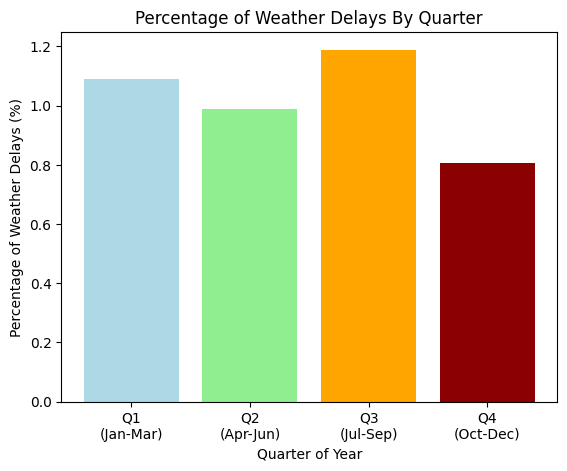

In [18]:
plt.bar(["Q1\n(Jan-Mar)", "Q2\n(Apr-Jun)", "Q3\n(Jul-Sep)", "Q4\n(Oct-Dec)"], frequencies['delayed'] / frequencies['not_delayed'] * 100, color=["lightblue", "lightgreen", "orange", "darkred"])
plt.title("Percentage of Weather Delays By Quarter")
plt.ylabel("Percentage of Weather Delays (%)")
plt.xlabel("Quarter of Year")
plt.show()

**Conclusion 4B:** From this graph, we can very clearly see that there is a slight difference in the percentage of weather delays between each quarter, confirming our earlier analysis that there is a statistically significant difference.